# 02 · Model Development and Evaluation

The training pipeline is the script `python -m credit_risk.train`, so results are reproducible and the same code produces the model the app uses. This notebook loads its outputs and evaluates them.

**Protocol**
1. One stratified split: 80% train, 20% test. The test set is used once, at the end.
2. Models are compared with **5-fold cross-validation on the training set only**.
3. Gradient boosting is tuned by random search, optimising **log loss**, which rewards accurate probabilities and not just correct ranking.
4. The decision threshold is chosen on **out-of-fold training predictions**, never on the test set.

In [1]:
import numpy as np
import pandas as pd

from credit_risk import config, data, evaluation, explain, fairness, plots, train

plots.set_style()
pd.set_option("display.precision", 3)
FIG, TABLES = config.FIGURES_DIR, config.TABLES_DIR

meta = train.load_metadata()
model = train.load_model()
pred = pd.read_csv(TABLES / "predictions.csv")
oof, test = pred[pred["split"] == "train_oof"], pred[pred["split"] == "test"]
threshold = meta["decision"]["threshold"]

## 1. Model comparison (cross-validation)

,roc_auc,roc_auc_std,pr_auc,brier,log_loss
model,,,,,
Baseline (predict average),0.500,0.000,0.221,0.172,0.528
Logistic regression,0.762,0.007,0.516,0.140,0.444
Gradient boosting (default settings),0.780,0.005,0.556,0.135,0.429
Gradient boosting (tuned),0.786,0.005,0.563,0.133,0.425


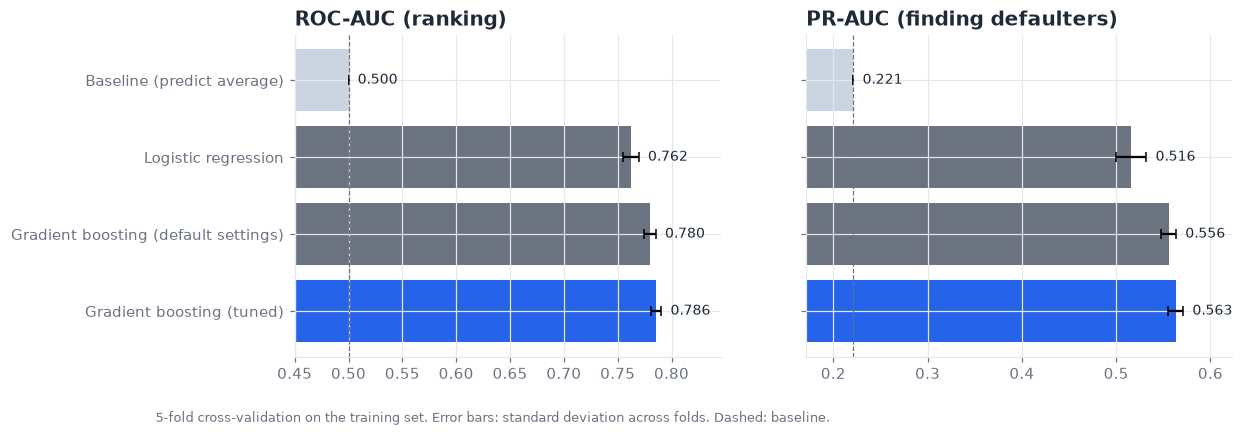

In [2]:
cv_table = pd.read_csv(TABLES / "cv_comparison.csv", index_col=0)
plots.model_comparison(cv_table, FIG / "02_model_comparison.png")
cv_table[["roc_auc", "roc_auc_std", "pr_auc", "brier", "log_loss"]]

- **Every model beats the baseline by a wide margin.** Because 22% of customers default, PR-AUC is the more demanding metric: the baseline scores 0.22, and the tuned model 0.56.
- **Feature engineering helped the linear model most.** Logistic regression on the raw columns scored 0.722 ROC-AUC (see the experiment in notebook 01). With the engineered features it reaches 0.762.
- **Gradient boosting wins** (0.786 ROC-AUC). Tuning added a small but consistent gain, larger than the fold-to-fold spread.

Best hyperparameters (the top few are almost tied, a sign the result isn't fragile):

In [3]:
pd.read_csv(TABLES / "tuning_top10.csv").head(5)

,min_samples_leaf,max_leaf_nodes,max_features,learning_rate,l2_regularization,log_loss,log_loss_std
0,100.0,15.0,0.5,0.02,1.0,0.425,0.003
1,100.0,15.0,0.8,0.05,10.0,0.426,0.002
2,50.0,15.0,0.8,0.05,1.0,0.426,0.002
3,20.0,15.0,0.5,0.05,0.0,0.426,0.002
4,50.0,15.0,0.8,0.10,10.0,0.426,0.002


## 2. Test-set performance

The test set is touched for the first time here:

In [4]:
pd.DataFrame(meta["test_scores"]).T

,roc_auc,pr_auc,brier,log_loss
Gradient boosting (tuned),0.780,0.558,0.135,0.429
Logistic regression,0.747,0.507,0.142,0.450


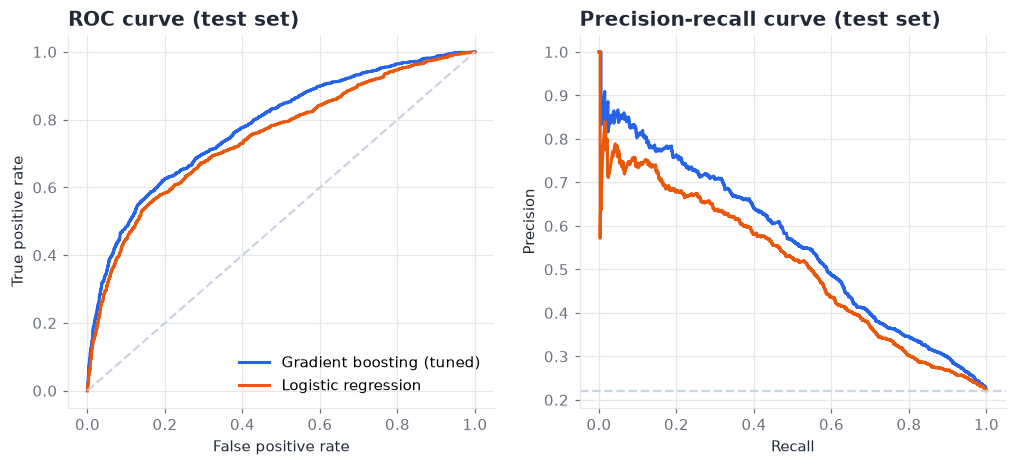

In [5]:
plots.roc_pr(test[config.TARGET].to_numpy(),
             {"Gradient boosting (tuned)": test["probability"].to_numpy(),
              "Logistic regression": test["probability_benchmark"].to_numpy()},
             FIG / "03_roc_pr.png");

Test ROC-AUC (0.780) is very close to the cross-validated estimate (0.786), so the model generalises as expected and was not overfit to the training data or to the tuning process.

## 3. Can the probabilities be trusted?

Decisions are made by comparing a probability with costs, so a predicted 30% must really mean about 30%:

,customers,predicted,observed
0,600,0.041,0.042
1,600,0.064,0.063
2,600,0.088,0.090
3,600,0.114,0.120
4,600,0.137,0.155
5,600,0.163,0.178
6,600,0.200,0.173
7,600,0.276,0.268
8,600,0.430,0.417
9,600,0.702,0.705


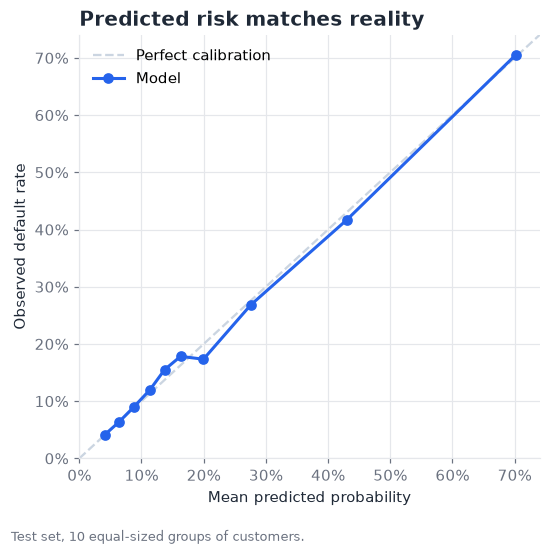

In [6]:
cal = evaluation.calibration_table(test[config.TARGET], test["probability"])
plots.calibration(cal, FIG / "04_calibration.png")
cal

Across all ten groups, predicted and actual default rates agree to within about 2 percentage points. Gradient boosting trained with log loss is well calibrated here, so no extra calibration step is needed.

## 4. From probabilities to decisions

The bank must decide **whom to flag for action**. Accuracy is the wrong yardstick, because the two mistakes have very different costs:

| Mistake | Consequence | Assumed cost |
|---|---|---|
| Missed defaulter (false negative) | Unpaid balance written off | 5 |
| False alarm (false positive) | Unnecessary call or limit review | 1 |

The 5:1 ratio is an assumption, not a fact; the app lets users change it. With calibrated probabilities, theory says to flag a customer when *p × 5 > (1 − p) × 1*, i.e. when **p > 1/6 ≈ 0.17**.

Threshold chosen on out-of-fold training predictions: 0.17 (theory: 0.167)


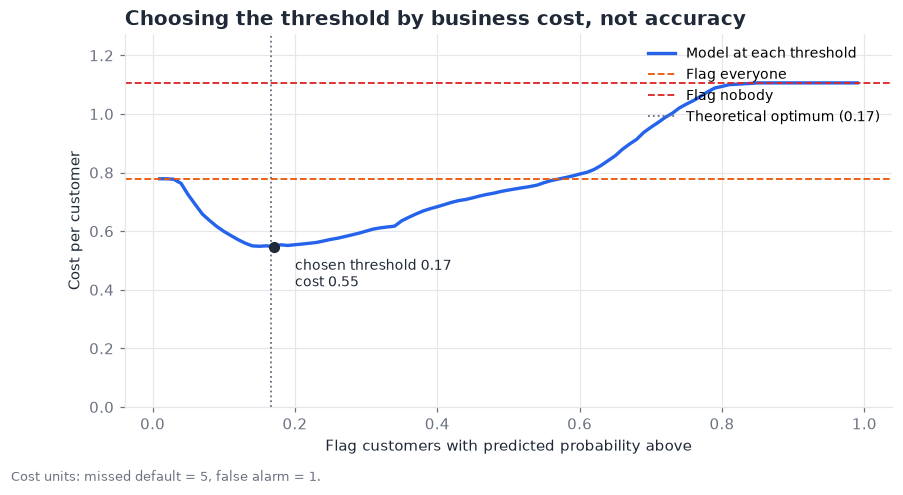

In [7]:
curve = evaluation.cost_curve(oof[config.TARGET], oof["probability"])
plots.cost_curve(curve, threshold, meta["decision"]["theoretical_threshold"],
                 evaluation.no_model_cost(oof[config.TARGET]), FIG / "05_cost_curve.png")
print(f"Threshold chosen on out-of-fold training predictions: {threshold:.2f} "
      f"(theory: {meta['decision']['theoretical_threshold']:.3f})")

The cost-minimising threshold found in the data (**0.17**) matches the theoretical value, which is another confirmation that the probabilities are well calibrated.

**Result on the test set at this threshold:**

In [8]:
d, nm = meta["test_decision"], meta["test_no_model_cost"]
summary = pd.Series({
    "Customers flagged": f"{d['flagged_rate']:.0%}",
    "Defaulters caught (recall)": f"{d['recall']:.0%}",
    "Flagged customers who default (precision)": f"{d['precision']:.0%}",
    "Cost per customer, model": f"{d['cost_per_customer']:.2f}",
    "Cost per customer, flag everyone": f"{nm['flag_everyone']:.2f}",
    "Cost per customer, flag nobody": f"{nm['flag_nobody']:.2f}",
    "Saving vs best no-model strategy": f"{1 - d['cost_per_customer'] / min(nm.values()):.0%}",
})
summary.to_frame("test set")

,test set
Customers flagged,42%
Defaulters caught (recall),72%
Flagged customers who default (precision),38%
"Cost per customer, model",0.57
"Cost per customer, flag everyone",0.78
"Cost per customer, flag nobody",1.11
Saving vs best no-model strategy,27%


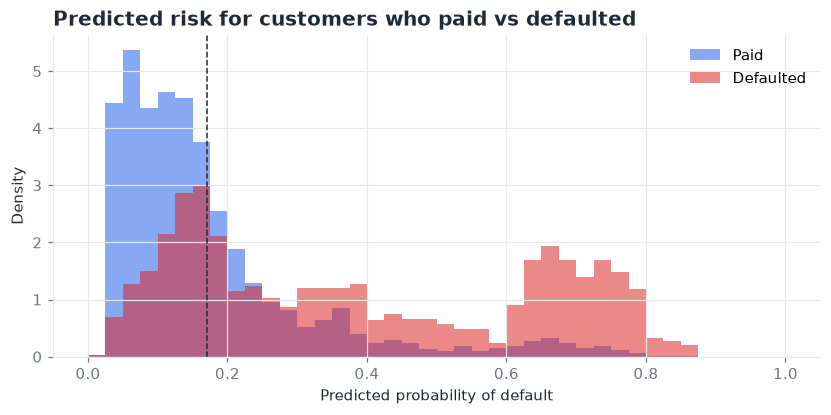

In [9]:
plots.score_distribution(test[config.TARGET], test["probability"], threshold, FIG / "06_score_distribution.png");

**Interpretation.** With these costs, the model flags 42% of customers and catches 72% of the defaulters. Only 38% of flagged customers actually default, but that's the right trade-off when a missed default costs five times a false alarm. The policy costs about **27% less** than the best strategy that uses no model (flagging everyone).

**Limitations**
- The data is from **one Taiwanese bank in 2005**. Customer behaviour, products and economic conditions differ today and elsewhere, so the model would need retraining and validation before any real use.
- The **costs are illustrative**. A real deployment would estimate them from the bank's own loss and operations data.
- The outcome is **one month ahead**; it says nothing about longer-term risk.